# 2. Data Science with Scikit-Learn: Pipelines for Time Series/non iid

**`sklearn` Paradigm**: `BaseEstimator`, `TransformerMixin`, and `RegressorMixin`.

**Custom Transformers**:
* `SensorClipper`: Cutting impossible sensor spikes (physical impossible values).
* `ForwardFillImputer`: Fills missing values (`NaN`) using previous valid measurements without future leakage.

**Custom Estimator**: Wrapping `statsmodels.tsa.arima.model.ARIMA` into an `sklearn` compatible estimator.

**The `Pipeline`**: Chaining data cleaning, imputation, and forecasting into a `sklearn` pipeline.

**Validation & Tuning**: Native Scikit-Learn `TimeSeriesSplit`, `GridSearchCV` parameter optimization, and `cross_validate`.

**Evaluation & Visualization**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

from statsmodels.tsa.arima.model import ARIMA
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
# hide warnings for demo
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.random.seed(1337)
print("imports ready!")


imports ready!


## 2.1 Generating Realistic Time-Series Sensor Data

Sensor data typically exhibits:
- Autoregressive dynamics ($	\text{AR}(1)$ / $\text{ARMA}(1, 1)$) + 24h periodicity.
- **Impossible physical readings** (e.g., negativ humidity or pressure).
- **Missing data `NaN`** (eg caused by sensor dropouts)

In [4]:
n_samples = 400
t = np.arange(n_samples)

# Simulate an AR(1) process with seasonal day cycle variation
# AR(1) recurrence: y_t = 0.75 * y_{t-1} + noise
phi = 0.75
ar_series = np.zeros(n_samples)
noise = np.random.normal(0, 1.0, size=n_samples)
for i in range(1, n_samples):
    ar_series[i] = phi * ar_series[i - 1] + noise[i]

day_cycle = 4.0 * np.sin(2 * np.pi * t / 24)
baseline = 20.0
clean_target = baseline + day_cycle + ar_series


# inject missing 20 values (NaNs) and 40 impossible spikes
n_missing = 20
n_impossible = 12

corrupted_series = clean_target.copy()

nan_indices = np.random.choice(np.arange(10, n_samples - 10), size=n_missing, replace=False)
corrupted_series[nan_indices] = np.nan

impossible_indices = np.random.choice(np.arange(10, n_samples - 10), size=n_impossible, replace=False)
corrupted_series[impossible_indices] = np.random.uniform(low=50, high=1_000, size=n_impossible) * np.random.choice([-1,1])

df = pd.DataFrame({
    "time_step": t,
    "sensor_value": corrupted_series
})

print(f"Total samples: {len(df)}")
print(f"Missing values (NaNs): {df["sensor_value"].isna().sum()}")
print(f"Values outside valid range [-10, 45]: {((df["sensor_value"] < -10) | (df["sensor_value"] > 45)).sum()}")

Total samples: 400
Missing values (NaNs): 19
Values outside valid range [-10, 45]: 12


## 2.2 The Scikit-Learn Paradigm: Custom Transformers

In `scikit-learn`, every data tranformer is structured like this:
- `fit(X, y=None)`: Computes and stores parameters from training array. (Must return `self`)
- `transform(X)`: Applies transformation and returns the processed matrix/array.

By inheriting from `BaseEstimator` and `TransformerMixin`, we automatically get `fit_transform()` and hyperparameter inspection for free!

Lets look at two domain-specific transformers:
1. `SensorClipper`: Clips impossible values to $[min\_val, max\_val]$.
2. `ForwardFillImputer`: Fills missing values by choosing last availabe value in time.

In [5]:
class SensorClipper(BaseEstimator, TransformerMixin):
    """Clips sensor values to a physically valid range [min_val, max_val]."""
    def __init__(self, min_val=0.0, max_val=45.0):
        self.min_val = min_val
        self.max_val = max_val
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X_out = np.asarray(X, dtype=float).copy() # always a good idea to use .copy on inputs. Sklearn can complain sometimes, if not done.
        
        X_out[X_out < self.min_val] = self.min_val
        X_out[X_out > self.max_val] = self.max_val
        
        return X_out


class ForwardFillImputer(BaseEstimator, TransformerMixin):
    """
    Imputes missing values (NaN) using the last observed entry (forward-fill).
    Falls back to back-fill or default_fill if the series starts with a missing value.
    """
    def __init__(self, default_fill=0.0):
        self.default_fill = default_fill
        self.learned_initial_val_ = None
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X_arr = np.asarray(X, dtype=float).copy()
        
        s = pd.Series(X_arr.ravel())
        s_imputed = s.ffill().fillna(self.default_fill) # bit hacky, but handles leading NaNs via bfill / default_fill
        
        return s_imputed.to_numpy().reshape(X_arr.shape)


### Quick Sanity Check: Test the Transformers in Isolation

In [6]:
sample_raw = df["sensor_value"].values
clipper = SensorClipper(min_val=0.0, max_val=45.0)
imputer = ForwardFillImputer()

cleaned_clipped = clipper.fit_transform(sample_raw)
cleaned_full = imputer.fit_transform(cleaned_clipped)

print(f"Raw NaNs: {np.isnan(sample_raw).sum():.1f} -> Imputed NaNs: {np.isnan(cleaned_full).sum():.1f}")
print(f"Raw Max:  {np.nanmax(sample_raw):.1f} -> Clipped Max:  {np.nanmax(cleaned_full):.1f}")
print(f"Raw Min: {np.nanmin(sample_raw):.1f} -> Clipped Min:  {np.nanmin(cleaned_full):.1f}")

Raw NaNs: 19.0 -> Imputed NaNs: 0.0
Raw Max:  26.2 -> Clipped Max:  26.2
Raw Min: -991.6 -> Clipped Min:  0.0


## 2.3 Custom Estimator: Wrapping `statsmodels` ARMA into Scikit-Learn

`statsmodels` has powerful time-series models like `ARIMA`, but its API differs from `scikit-learn` (`fit()` returns a `Results` object rather than `self`).

To put `statsmodels` into an `sklearn.pipeline.Pipeline`, we inherit from `BaseEstimator` and `RegressorMixin` and wrap the `ARIMA(p, d, q)` functions.

In [7]:
class StatsmodelsARMAEstimator(BaseEstimator, RegressorMixin):
    """
    Scikit-learn compatible wrapper around statsmodels.tsa.arima.model.ARIMA.
    """
    def __init__(self, order=(1, 0, 1)):
        self.order = order
        self.model_res_ = None
        self.fitted_y_ = None
        
    def fit(self, X, y=None):
        # For univariate time series, X or y contains the series values
        data = y if y is not None else X
        series = np.asarray(data, dtype=float).ravel()
        
        # Fit statsmodels ARIMA
        model = ARIMA(series, order=self.order)
        self.model_res_ = model.fit()
        self.fitted_y_ = self.model_res_.fittedvalues
        return self
        
    def predict(self, X):
        n_steps = len(X)
        forecast_res = self.model_res_.forecast(steps=n_steps)
        return np.asarray(forecast_res)


## 2.4 Composing the Scikit-Learn `Pipeline`

The pipeline chains preprocessing and estimator together so that *every run* is the exact same procedure and we cant fuck up the preprocess ordering, which can easily happen in jupyter notebooks:
$$\text{Raw Sensor Data} \xrightarrow{\text{SensorClipper}} \text{Clipped Senor Data} \xrightarrow{\text{ForwardFillImputer}} \text{Clean Data} \xrightarrow{\text{ARMA}} \text{Forecast}$$

In [8]:
ts_pipeline = Pipeline([
    ("clipper", SensorClipper(min_val=0.0, max_val=45.0)),
    ("imputer", ForwardFillImputer()),
    ("arma_model", StatsmodelsARMAEstimator(order=(2, 0, 2)))
])

print("Constructed Pipeline:")
ts_pipeline

Constructed Pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clipper', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,min_val,0.0
,max_val,45.0
,default_fill,0.0
Name,Type,Value
learned_initial_val_,NoneType,None
,order,"(2, ...)"
Name,Type,Value


## 2.5 Time-Series Cross-Validation (`TimeSeriesSplit`)

### Why standard K-Fold is wrong for Time Series:
Standard K-Fold randomly shuffles samples into intervalls. In time-series data, this causes **lookahead bias (data leakage)**: 

=> *eg. predicting $y_t$ using information from $y_{t+5}$*

`TimeSeriesSplit` provides an expanding training window where training always strictly goes before testing.

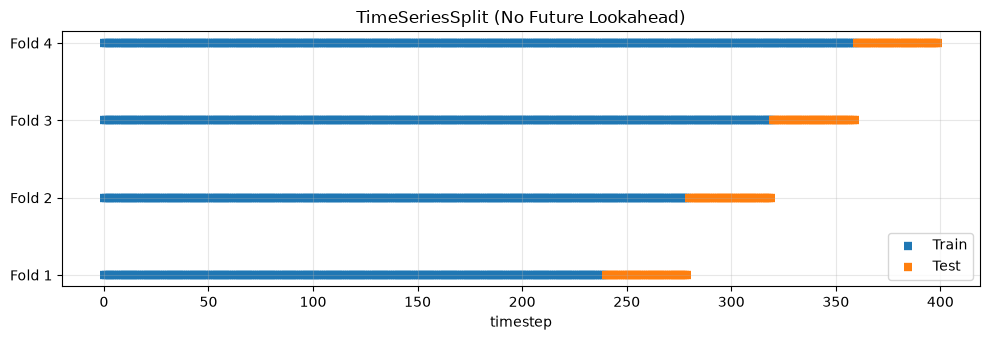

In [9]:
n_splits = 4
tscv = TimeSeriesSplit(n_splits=n_splits, test_size=40)

fig, ax = plt.subplots(figsize=(10, 3.5))
for fold_idx, (train_idx, test_idx) in enumerate(tscv.split(df["sensor_value"])):
    ax.scatter(train_idx, [fold_idx] * len(train_idx), color="tab:blue", marker="_", lw=6, label="Train" if fold_idx == 0 else "")
    ax.scatter(test_idx, [fold_idx] * len(test_idx), color="tab:orange", marker="_", lw=6, label="Test" if fold_idx == 0 else "")

ax.set_yticks(range(n_splits))
ax.set_yticklabels([ f"Fold {i+1}" for i in range(n_splits) ])
ax.set_xlabel("timestep")
ax.set_title("TimeSeriesSplit (No Future Lookahead)")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2.6 Native Scikit-Learn Parameter Selection & Cross-Validation

Instead of writing manual `for`-loops for checking hyperparameter configurations, Scikit-Learn provides built-in tools that natively support `TimeSeriesSplit`:

1. **`GridSearchCV`**: Tests candidate hyperparameter configurations across time-series folds to discover the optimal model without data leakage.
2. **`cross_validate`**: Executes cross-validation across multiple eval metrics (`RMSE`, `MAE`) simultaneously.


In [10]:
X_raw = df["sensor_value"].values
y_true = clean_target

param_grid = {
    "arma_model__order": [
        (1, 0, 0),
        (1, 0, 1),
        (2, 0, 0),
        (2, 0, 1),
        (2, 0, 2),
    ]
}

grid_search = GridSearchCV(
    estimator=ts_pipeline,
    param_grid=param_grid,
    cv=tscv, # 4 splits
    scoring="neg_root_mean_squared_error", # More easily interpratable then mean squared error (kinda like standard diviation vs variance)
    n_jobs=1,
    refit=True,
)

print("Running GridSearchCV...")
grid_search.fit(X_raw, y_true)

print(f"Optimal Parameter: {grid_search.best_params_}")
print(f"Best Cross-Validation RMSE: {-grid_search.best_score_:.2f}\n")

Running GridSearchCV...
Optimal Parameter: {'arma_model__order': (2, 0, 2)}
Best Cross-Validation RMSE: 1.66



In [11]:
cv_results = cross_validate(
    estimator=grid_search.best_estimator_,
    X=X_raw,
    y=y_true,
    cv=tscv,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
    },
)

cv_df = pd.DataFrame({
    "Fold": np.arange(1, len(cv_results["test_RMSE"]) + 1),
    "RMSE": -cv_results["test_RMSE"],
    "MAE": -cv_results["test_MAE"],
})

print("=== Native Scikit-Learn cross_validate Results ===")
print(cv_df.to_string(index=False))
print(f"\nMean RMSE: {cv_df["RMSE"].mean():.2f} ± {cv_df["RMSE"].std():.2f}")
print(f"Mean MAE:  {cv_df["MAE"].mean():.2f} ± {cv_df["MAE"].std():.2f}")


=== Native Scikit-Learn cross_validate Results ===
 Fold     RMSE      MAE
    1 1.522031 1.159944
    2 1.877495 1.364025
    3 1.538781 1.277046
    4 1.690719 1.424835

Mean RMSE: 1.66 ± 0.17
Mean MAE:  1.31 ± 0.11


## 2.7 Visualizing Model Predictions vs. Ground Truth

We now use the fitted fold estimators returned directly by `cross_validate` (`cv_results["estimator"]`) and look at the forecasts vs the actual ground truth.


AttributeError: 'SensorClipper' object has no attribute 'predict'

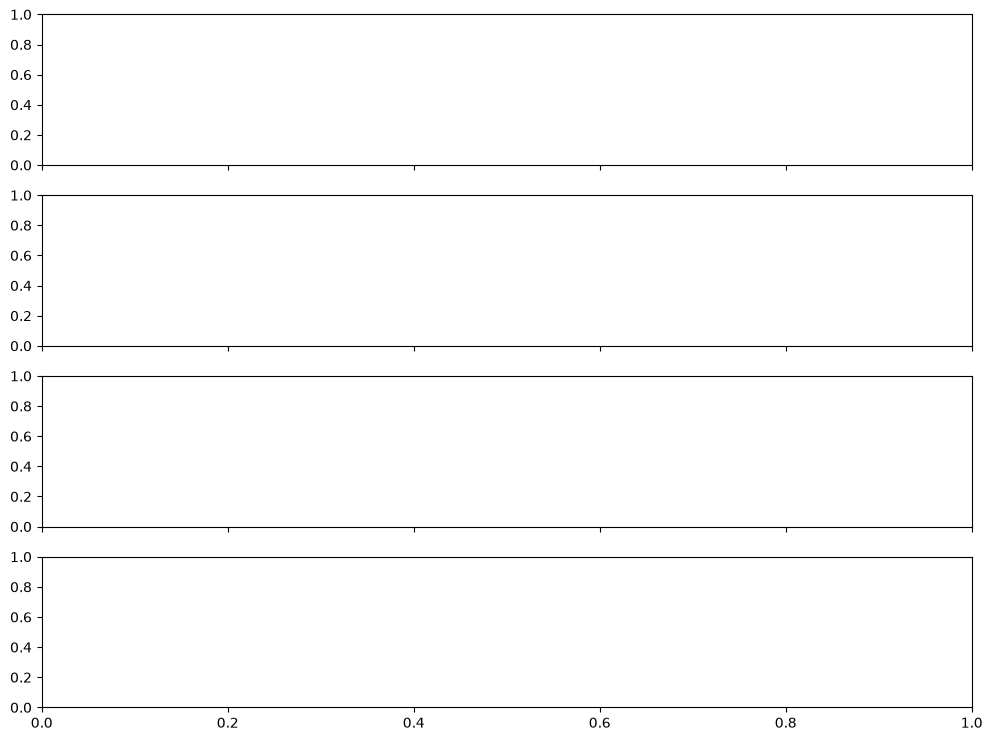

In [12]:
fig, axes = plt.subplots(n_splits, 1, figsize=(12, 9), sharex=True)

for fold, ((train_idx, test_idx), est) in enumerate(zip(tscv.split(X_raw), grid_search.best_estimator_)):
    ax = axes[fold]
    y_test_pred = est.predict(X_raw[test_idx])
    fold_rmse = -cv_results["test_RMSE"][fold]
    
    # recent history before test fold
    history_start = max(0, test_idx[0] - 60) #max() ensure no negtive indecies from -60 offset
    ax.plot(range(history_start, test_idx[0]), y_true[history_start:test_idx[0]], 
            color="tab:blue", label="History" if fold == 0 else "")
    
    #  ground truth
    ax.plot(test_idx, y_true[test_idx], color="black", lw=2, label="Ground Truth" if fold == 0 else "")
    
    # best pipeline prediction
    ax.plot(test_idx, y_test_pred, color="tab:red", linestyle="--", lw=2.2, 
            label=f"Best ARMA Forecast (RMSE: {fold_rmse:.2f})" if fold == 0 else f"Best ARMA Forecast (RMSE: {fold_rmse:.2f})")
    
    ax.axvline(test_idx[0], color="gray", linestyle=":", alpha=0.8)
    ax.set_ylabel(f"Fold {fold+1}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time Step Index")
best_order_str = grid_search.best_params_["arma_model__order"]
plt.suptitle(f"Forecasts Across TimeSeriesSplit Folds \n GridSearchCV Best Order: {best_order_str}", 
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
